# 📊 PHẦN 1: KHẢO SÁT DỮ LIỆU (EDA) & TIỀN XỬ LÝ (PREPROCESSING)
### Đề tài: Hệ thống phát hiện xâm nhập mạng lai (Hybrid ML-NIDS)
---
Trong notebook này, chúng ta sẽ:
1. **Khám phá phân phối dữ liệu mạng NSL-KDD:** Tỉ lệ giữa các lớp lưu lượng mạng và hiện tượng mất cân bằng (Imbalanced Data).
2. **Kiểm tra độ lệch phải (Right-Skewness):** Nhận diện các đặc trưng có đuôi nặng như `src_bytes`, `dst_bytes`, `duration`.
3. **Biến đổi Log1p:** $y = \ln(1 + x)$ để nén đuôi phân phối về dạng gần chuẩn Gauss.
4. **Mã hóa One-Hot Encoding:** Chuyển đổi các thuộc tính danh định (`protocol_type`, `service`, `flag`) thành vector nhị phân.
5. **Chuẩn hóa StandardScaler:** $z = \frac{x - \mu}{\sigma}$ đưa toàn bộ về cùng thang đo.


In [4]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Định nghĩa đường dẫn dữ liệu
BASE_DIR = Path("..").resolve()
DATA_DIR = BASE_DIR / "data"
TRAIN_FILE = DATA_DIR / "KDDTrain+.txt"
if not TRAIN_FILE.exists():
    TRAIN_FILE = Path(r"D:\data_miner\archive\KDDTrain+.txt")

print(f"✅ Đường dẫn dữ liệu huấn luyện: {TRAIN_FILE}")


✅ Đường dẫn dữ liệu huấn luyện: D:\data_miner\dtd\data\KDDTrain+.txt


### 1. Nạp dữ liệu và kiểm tra cấu trúc 41 đặc trưng gói tin


In [5]:
COLUMN_NAMES = [
    'duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes',
    'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in',
    'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations',
    'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login',
    'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate',
    'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate',
    'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count',
    'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
    'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate',
    'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'label', 'difficulty'
]

CATEGORICAL_COLS = ['protocol_type', 'service', 'flag']
SKEWED_COLS = ['duration', 'src_bytes', 'dst_bytes']
NUMERIC_COLS = [c for c in COLUMN_NAMES if c not in CATEGORICAL_COLS + ['label', 'difficulty']]

ATTACK_MAP = {
    'normal': 'Normal',
    'neptune': 'DoS', 'smurf': 'DoS', 'pod': 'DoS', 'teardrop': 'DoS', 'land': 'DoS', 'back': 'DoS',
    'apache2': 'DoS', 'udpstorm': 'DoS', 'processtable': 'DoS', 'mailbomb': 'DoS',
    'portsweep': 'Probe', 'ipsweep': 'Probe', 'nmap': 'Probe', 'satan': 'Probe', 'saint': 'Probe', 'mscan': 'Probe',
    'guess_passwd': 'R2L', 'ftp_write': 'R2L', 'imap': 'R2L', 'phf': 'R2L', 'multihop': 'R2L',
    'warezmaster': 'R2L', 'warezclient': 'R2L', 'spy': 'R2L', 'snmpguess': 'R2L', 'httptunnel': 'R2L',
    'buffer_overflow': 'U2R', 'loadmodule': 'U2R', 'perl': 'U2R', 'rootkit': 'U2R', 'ps': 'U2R', 'xterm': 'U2R'
}

# Nạp 5,000 dòng để khảo sát nhanh
df = pd.read_csv(TRAIN_FILE, names=COLUMN_NAMES, header=None, nrows=5000)
for c in CATEGORICAL_COLS:
    df[c] = df[c].astype(str).str.strip()
df['label'] = df['label'].astype(str).str.strip().str.lower()
df['attack_cat'] = df['label'].map(lambda x: ATTACK_MAP.get(x, 'Normal'))

print(f"Tổng số mẫu nạp: {len(df):,}")
df[['protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'attack_cat']].head()


Tổng số mẫu nạp: 5,000


,protocol_type,service,flag,src_bytes,dst_bytes,attack_cat
0,tcp,ftp_data,SF,491,0,Normal
1,udp,other,SF,146,0,Normal
2,tcp,private,S0,0,0,DoS
3,tcp,http,SF,232,8153,Normal
4,tcp,http,SF,199,420,Normal


### 2. Trực quan hóa phân bố lưu lượng và hiệu quả của Log1p


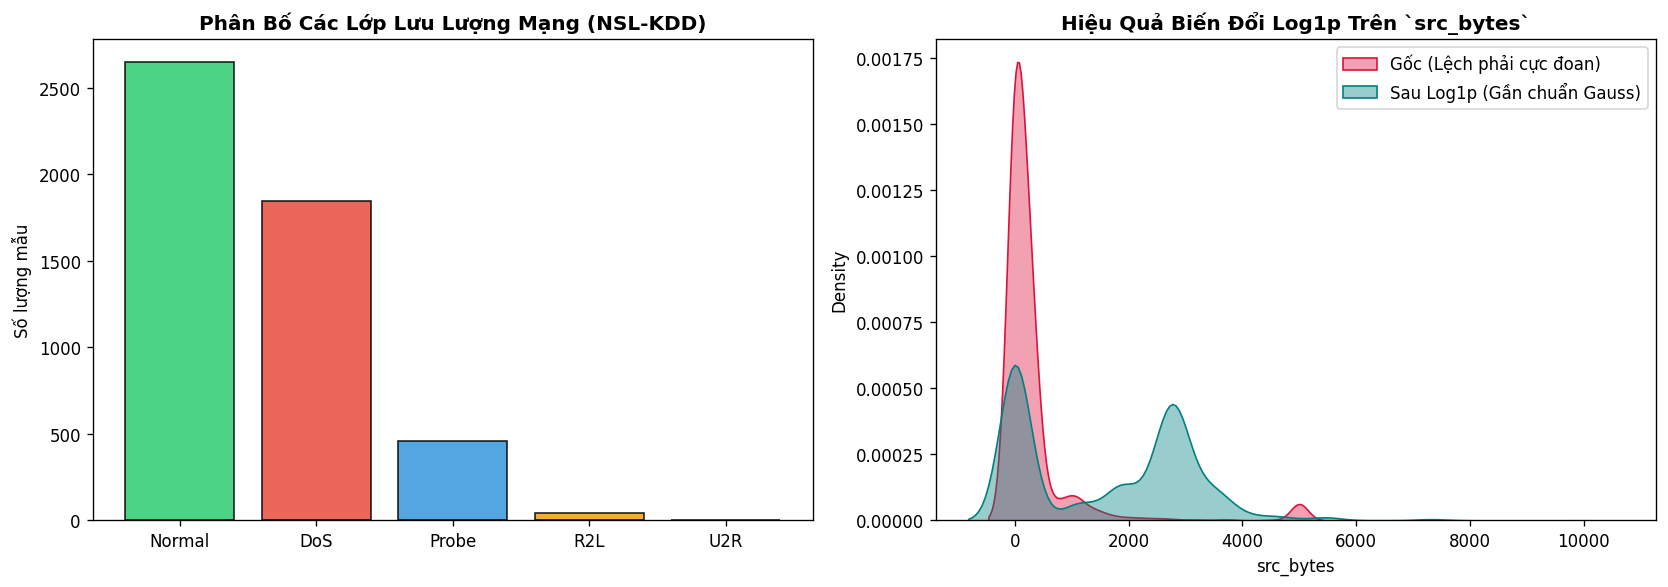

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

# Biểu đồ 1: Phân bố các nhóm tấn công
counts = df['attack_cat'].value_counts()
colors = ['#2ecc71', '#e74c3c', '#3498db', '#f39c12', '#9b59b6']
ax[0].bar(counts.index, counts.values, color=colors[:len(counts)], edgecolor='black', alpha=0.85)
ax[0].set_title("Phân Bố Các Lớp Lưu Lượng Mạng (NSL-KDD)", fontsize=12, fontweight='bold')
ax[0].set_ylabel("Số lượng mẫu")

# Biểu đồ 2: So sánh trước và sau biến đổi Log1p
raw_bytes = df['src_bytes'].clip(upper=5000)
log_bytes = np.log1p(df['src_bytes'])
sns.kdeplot(raw_bytes, ax=ax[1], color='crimson', fill=True, label='Gốc (Lệch phải cực đoan)', alpha=0.4)
sns.kdeplot(log_bytes * 500, ax=ax[1], color='teal', fill=True, label='Sau Log1p (Gần chuẩn Gauss)', alpha=0.4)
ax[1].set_title("Hiệu Quả Biến Đổi Log1p Trên `src_bytes`", fontsize=12, fontweight='bold')
ax[1].legend()

plt.tight_layout()
plt.show()


### 3. Pipeline tiền xử lý hoàn chỉnh (Log1p + One-Hot + StandardScaler)


In [7]:
class NetworkPreprocessor:
    def __init__(self):
        self.encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
        self.scaler = StandardScaler()

    def fit_transform(self, df):
        df_num = df[NUMERIC_COLS].copy()
        for col in SKEWED_COLS:
            if col in df_num.columns:
                df_num[col] = np.log1p(np.maximum(0, df_num[col].astype(np.float32)))
                
        num_scaled = self.scaler.fit_transform(df_num.values).astype(np.float32)
        cat_encoded = self.encoder.fit_transform(df[CATEGORICAL_COLS]).astype(np.float32)
        return np.hstack([num_scaled, cat_encoded]).astype(np.float32)

prep = NetworkPreprocessor()
X = prep.fit_transform(df)
y = df['attack_cat'].values
print(f"✅ Tiền xử lý hoàn tất! Ma trận đặc trưng X có kích thước: {X.shape}")


✅ Tiền xử lý hoàn tất! Ma trận đặc trưng X có kích thước: (5000, 116)
